# ML PD Model: Monotonic Constraints, SHAP & Calibration

Gradient boosting usually beats a scorecard at ranking borrowers, but a model-risk team will only approve it if it behaves sensibly, gives probabilities at the right level, and can explain every decline. This notebook builds a boosted PD model that meets those three conditions and measures what each one costs.

**What it does.** It builds a gradient-boosting PD model on the Home Credit loan applications, with features engineered in SQL from the credit-bureau, previous-application and instalment histories.

It compares an unconstrained LightGBM with one whose key risk drivers are forced to be monotonic, and measures what the constraints cost in accuracy and what they buy in behaviour. It then calibrates the PDs (Platt and isotonic) and explains every decision with TreeSHAP and reason codes.

**Data.** Home Credit Default Risk (Kaggle competition): 307,511 applications with 8.1% defaults, plus 1.7 million bureau records, 1.7 million previous applications and 13.6 million instalment payments.

**Methods.** DuckDB feature aggregation, a logistic-regression benchmark, LightGBM with and without `monotone_constraints`, and ICE-based monotonicity tests.

The calibration work covers class weighting and its effect on probabilities, and Platt scaling against isotonic regression, scored with the Brier score, expected calibration error and reliability curves. TreeSHAP gives global and local explanations.

**Key output.** Discrimination of the three models, the accuracy cost of monotonicity, calibration before and after, SHAP drivers, and an explained decision for a single applicant.

## 1. Why a constrained, calibrated challenger

Gradient boosting is now the standard **challenger** to a scorecard and, in many lenders, the production model. Model-risk teams accept it under three conditions:

1. **Economically sensible behaviour.** A borrower with a better bureau score must never get a higher PD, everything else equal. Unconstrained trees can learn local reversals from noise; **monotonic constraints** rule them out.
2. **Calibrated probabilities.** Rankings are enough to approve or decline, but PDs feed pricing, IFRS 9 provisions and capital, so their level must be right. Class weighting, used to handle the 8% default rate, distorts that level.
3. **Explanations.** Every decline needs reasons (ECOA adverse-action notices in the U.S.; GDPR rights in Europe), and the validator needs to see which variables drive the model. TreeSHAP gives exact Shapley values for trees.

## 2. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")


# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import duckdb
import lightgbm as lgb
from sklearn.calibration import calibration_curve
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    brier_score_loss,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

SEED = 7
COMPETITION = "home-credit-default-risk"
FILES = [
    "application_train.csv",
    "bureau.csv",
    "previous_application.csv",
    "installments_payments.csv",
]
TARGET_APPROVAL = 0.80

print(
    f"lightgbm {lgb.__version__} · duckdb {duckdb.__version__} · run on"
    f" {dt.date.today():%Y-%m-%d}"
)

lightgbm 4.7.0 · duckdb 1.5.6 · run on 2026-10-19


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"


# --- Kaggle downloads
# The kaggle package authenticates with KAGGLE_API_TOKEN (read from .env above)
# or with
# ~/.kaggle/access_token / ~/.kaggle/kaggle.json. It is imported here, after
# load_dotenv, on purpose.
import zipfile


def kaggle_api():
    from kaggle.api.kaggle_api_extended import KaggleApi

    api = KaggleApi()
    api.authenticate()
    return api


def kaggle_file(ref, filename, competition=False):
    """
    Download one file of a Kaggle dataset or competition into data/ (once) and
    return its local path.
    """
    target = DATA_DIR / filename
    if target.exists():
        return target
    api = kaggle_api()
    if competition:
        api.competition_download_file(ref, filename, path=DATA_DIR, quiet=True)
    else:
        api.dataset_download_file(ref, filename, path=DATA_DIR, quiet=True)
    zipped = DATA_DIR / f"{Path(filename).name}.zip"
    # large files arrive zipped
    if zipped.exists():
        with zipfile.ZipFile(zipped) as z:
            z.extractall(DATA_DIR)
        zipped.unlink()
    if not target.exists():
        raise FileNotFoundError(
            f"{filename} not found after download from {ref}"
        )
    return target

## 3. Data and SQL feature engineering

The four files are downloaded once from the Kaggle competition (the rules have to be accepted on Kaggle by the account that owns the token). DuckDB reads the CSVs directly and aggregates the history tables to one row per application:

| Source | Features |
|---|---|
| Application | external scores 1–3, age, years employed, income, credit, annuity, goods price and their ratios, region rating, document and contact flags |
| Credit bureau | number of credits, active credits, share closed, total debt / total credit, maximum days overdue, current overdue amount, recency |
| Previous Home Credit applications | number, share refused, average amount applied vs granted |
| Instalments | share paid late, average and maximum days late, share under-paid |

`DAYS_EMPLOYED = 365243` is a known placeholder for pensioners and unemployed applicants; it becomes missing plus a flag. Gender and family status are excluded from the model.

In [3]:
paths = {f: kaggle_file(COMPETITION, f, competition=True) for f in FILES}
con = duckdb.connect()
con.execute("SET enable_progress_bar = false")
for f, p in paths.items():
    con.execute(
        f"CREATE OR REPLACE VIEW {f.split('.')[0]} AS SELECT * FROM"
        f" read_csv_auto('{p.as_posix()}', sample_size=-1)"
    )

feat = con.execute("""
WITH bur AS (
    SELECT SK_ID_CURR,
           COUNT(*)                                                    AS bureau_n_credits,
           AVG(CASE WHEN CREDIT_ACTIVE = 'Active' THEN 1 ELSE 0 END)   AS bureau_active_share,
           SUM(COALESCE(AMT_CREDIT_SUM_DEBT, 0)) / NULLIF(SUM(AMT_CREDIT_SUM), 0) AS bureau_debt_to_credit,
           MAX(CREDIT_DAY_OVERDUE)                                     AS bureau_max_days_overdue,
           SUM(COALESCE(AMT_CREDIT_SUM_OVERDUE, 0))                    AS bureau_overdue_amount,
           -MAX(DAYS_CREDIT) / 365.25                                  AS bureau_years_since_last_credit
    FROM bureau GROUP BY 1),
prev AS (
    SELECT SK_ID_CURR,
           COUNT(*)                                                     AS prev_n_applications,
           AVG(CASE WHEN NAME_CONTRACT_STATUS = 'Refused' THEN 1 ELSE 0 END) AS prev_refused_share,
           AVG(AMT_CREDIT / NULLIF(AMT_APPLICATION, 0))                 AS prev_granted_to_applied
    FROM previous_application GROUP BY 1),
inst AS (
    SELECT SK_ID_CURR,
           AVG(CASE WHEN DAYS_ENTRY_PAYMENT > DAYS_INSTALMENT THEN 1 ELSE 0 END) AS inst_late_share,
           AVG(GREATEST(DAYS_ENTRY_PAYMENT - DAYS_INSTALMENT, 0))      AS inst_avg_days_late,
           MAX(DAYS_ENTRY_PAYMENT - DAYS_INSTALMENT)                   AS inst_max_days_late,
           AVG(CASE WHEN AMT_PAYMENT < 0.99 * AMT_INSTALMENT THEN 1 ELSE 0 END) AS inst_underpaid_share
    FROM installments_payments GROUP BY 1)
SELECT a.SK_ID_CURR, a.TARGET, a.CODE_GENDER,
       a.EXT_SOURCE_1, a.EXT_SOURCE_2, a.EXT_SOURCE_3,
       -a.DAYS_BIRTH / 365.25                                           AS age_years,
       CASE WHEN a.DAYS_EMPLOYED = 365243 THEN NULL ELSE -a.DAYS_EMPLOYED / 365.25 END AS years_employed,
       CASE WHEN a.DAYS_EMPLOYED = 365243 THEN 1 ELSE 0 END             AS not_employed_flag,
       a.AMT_INCOME_TOTAL AS income, a.AMT_CREDIT AS credit, a.AMT_ANNUITY AS annuity, a.AMT_GOODS_PRICE AS goods_price,
       a.AMT_CREDIT / NULLIF(a.AMT_GOODS_PRICE, 0)                      AS credit_to_goods,
       a.AMT_ANNUITY / NULLIF(a.AMT_INCOME_TOTAL, 0)                    AS annuity_to_income,
       a.AMT_CREDIT / NULLIF(a.AMT_ANNUITY, 0)                          AS credit_term_months_proxy,
       a.AMT_CREDIT / NULLIF(a.AMT_INCOME_TOTAL, 0)                     AS credit_to_income,
       a.REGION_RATING_CLIENT_W_CITY AS region_rating, a.REGION_POPULATION_RELATIVE AS region_population,
       -a.DAYS_ID_PUBLISH / 365.25                                       AS years_since_id_change,
       -a.DAYS_LAST_PHONE_CHANGE / 365.25                                AS years_since_phone_change,
       a.FLAG_OWN_CAR, a.FLAG_OWN_REALTY, a.CNT_CHILDREN AS n_children, a.OWN_CAR_AGE AS car_age,
       a.NAME_CONTRACT_TYPE, a.NAME_INCOME_TYPE, a.NAME_EDUCATION_TYPE, a.NAME_HOUSING_TYPE, a.OCCUPATION_TYPE, a.ORGANIZATION_TYPE,
       a.AMT_REQ_CREDIT_BUREAU_YEAR AS bureau_enquiries_year,
       bur.* EXCLUDE (SK_ID_CURR), prev.* EXCLUDE (SK_ID_CURR), inst.* EXCLUDE (SK_ID_CURR)
FROM application_train a
LEFT JOIN bur USING (SK_ID_CURR) LEFT JOIN prev USING (SK_ID_CURR) LEFT JOIN inst USING (SK_ID_CURR)
ORDER BY a.SK_ID_CURR                     -- fixed row order: DuckDB joins run in parallel, the split must not depend on it
""").df()
CATEGORICAL = [
    "FLAG_OWN_CAR",
    "FLAG_OWN_REALTY",
    "NAME_CONTRACT_TYPE",
    "NAME_INCOME_TYPE",
    "NAME_EDUCATION_TYPE",
    "NAME_HOUSING_TYPE",
    "OCCUPATION_TYPE",
    "ORGANIZATION_TYPE",
]
for c in CATEGORICAL:
    feat[c] = feat[c].astype("category")
FEATURES = [
    c for c in feat.columns if c not in ("SK_ID_CURR", "TARGET", "CODE_GENDER")
]
print(
    f"{len(feat):,} applications · default rate {feat['TARGET'].mean():.2%} ·"
    f" {len(FEATURES)} features · bureau history for"
    f" {feat['bureau_n_credits'].notna().mean():.0%}, instalment history for"
    f" {feat['inst_late_share'].notna().mean():.0%}"
)
feat[FEATURES].describe().T[["count", "mean", "50%"]].head(45)

307,511 applications · default rate 8.07% · 42 features · bureau history for 86%, instalment history for 95%


,count,mean,50%
EXT_SOURCE_1,"134,133.00",0.50,0.51
EXT_SOURCE_2,"306,851.00",0.51,0.57
EXT_SOURCE_3,"246,546.00",0.51,0.54
age_years,"307,511.00",43.91,43.12
years_employed,"252,137.00",6.53,4.51
not_employed_flag,"307,511.00",0.18,0.00
income,"307,511.00","168,797.92","147,150.00"
credit,"307,511.00","599,026.00","513,531.00"
annuity,"307,499.00","27,108.57","24,903.00"
goods_price,"307,233.00","538,396.21","450,000.00"


## 4. Samples and the monotonic constraints

60% of applications train the models, 20% are kept to calibrate the PDs and 20% are the untouched test set (stratified on default). The constraints encode the credit officer's prior: $+1$ means the PD may only rise with the feature, $-1$ only fall. Features with no clear economic direction (income, region, amounts) stay unconstrained.

In [4]:
train, rest = train_test_split(
    feat, test_size=0.4, stratify=feat["TARGET"], random_state=SEED
)
calib, test = train_test_split(
    rest, test_size=0.5, stratify=rest["TARGET"], random_state=SEED
)
y_tr, y_ca, y_te = (d["TARGET"].to_numpy() for d in (train, calib, test))

MONOTONE = {
    "EXT_SOURCE_1": -1,
    "EXT_SOURCE_2": -1,
    "EXT_SOURCE_3": -1,
    "age_years": -1,
    "years_employed": -1,
    "credit_to_goods": +1,
    "annuity_to_income": +1,
    "inst_late_share": +1,
    "inst_avg_days_late": +1,
    "inst_underpaid_share": +1,
    "bureau_debt_to_credit": +1,
    "bureau_max_days_overdue": +1,
    "prev_refused_share": +1,
    "bureau_enquiries_year": +1,
}
constraints = [MONOTONE.get(c, 0) for c in FEATURES]
print(
    f"train {len(train):,} · calibration {len(calib):,} · test {len(test):,} ·"
    f" {sum(c != 0 for c in constraints)} constrained features"
)
pd.Series(MONOTONE, name="direction of PD").to_frame().T

train 184,506 · calibration 61,502 · test 61,503 · 14 constrained features


,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,age_years,years_employed,credit_to_goods,annuity_to_income,inst_late_share,inst_avg_days_late,inst_underpaid_share,bureau_debt_to_credit,bureau_max_days_overdue,prev_refused_share,bureau_enquiries_year
direction of PD,-1,-1,-1,-1,-1,1,1,1,1,1,1,1,1,1


## 5. Three models

- **Logistic regression** on the 20 most important numeric features (median-imputed, standardised): the transparent benchmark.
- **LightGBM, unconstrained.**
- **LightGBM, monotonic:** same hyper-parameters plus the constraints, enforced with LightGBM's `intermediate` method. A third fit uses the `advanced` method, which is supposed to be less restrictive; section 6 shows why it is not used.

Both LightGBMs use class weighting (`is_unbalance`), as is common for rare defaults, and early stopping on an inner 15% of the training sample. The number of trees is chosen by early stopping; nothing is tuned on the test set.

In [5]:
Xtr_in, Xtr_es, ytr_in, ytr_es = train_test_split(
    train[FEATURES], y_tr, test_size=0.15, stratify=y_tr, random_state=SEED
)
params = dict(
    n_estimators=4_000,
    learning_rate=0.03,
    num_leaves=31,
    min_child_samples=200,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.6,
    reg_lambda=10.0,
    is_unbalance=True,
    metric="auc",
    random_state=SEED,
    verbose=-1,
)
models = {}
for name, extra in [
    ("LightGBM unconstrained", {}),
    (
        "LightGBM monotonic",
        {
            "monotone_constraints": constraints,
            "monotone_constraints_method": "intermediate",
        },
    ),
    (
        "LightGBM monotonic (advanced)",
        {
            "monotone_constraints": constraints,
            "monotone_constraints_method": "advanced",
        },
    ),
]:
    m = lgb.LGBMClassifier(**params, **extra)
    m.fit(
        Xtr_in,
        ytr_in,
        eval_set=[(Xtr_es, ytr_es)],
        callbacks=[
            lgb.early_stopping(200, first_metric_only=True, verbose=False)
        ],
    )
    models[name] = m
    print(f"{name}: {m.best_iteration_} trees")

gain = pd.Series(
    models["LightGBM unconstrained"].booster_.feature_importance("gain"),
    index=FEATURES,
).sort_values(ascending=False)
LOGIT_FEATURES = [c for c in gain.index if c not in CATEGORICAL][:20]
med = train[LOGIT_FEATURES].median()
logit = make_pipeline(
    StandardScaler(), LogisticRegression(max_iter=2_000, C=1.0)
)
logit.fit(train[LOGIT_FEATURES].fillna(med), y_tr)


def predict(name, frame):
    if name == "Logistic":
        return logit.predict_proba(frame[LOGIT_FEATURES].fillna(med))[:, 1]
    return models[name].predict_proba(frame[FEATURES])[:, 1]


NAMES = [
    "Logistic",
    "LightGBM unconstrained",
    "LightGBM monotonic",
    "LightGBM monotonic (advanced)",
]
p_te = {n: predict(n, test) for n in NAMES}
rng = np.random.default_rng(SEED)
boot = {n: [] for n in NAMES}
for _ in range(300):
    i = rng.integers(0, len(y_te), len(y_te))
    for n in NAMES:
        boot[n].append(roc_auc_score(y_te[i], p_te[n][i]))
d_mono = np.array(boot["LightGBM monotonic"]) - np.array(
    boot["LightGBM unconstrained"]
)
disc = pd.DataFrame({
    n: {
        "AUC": roc_auc_score(y_te, p_te[n]),
        "Gini": 2 * roc_auc_score(y_te, p_te[n]) - 1,
        "Gini 95% CI": (
            f"{2 * np.percentile(boot[n], 2.5) - 1:.3f}–{2 * np.percentile(boot[n], 97.5) - 1:.3f}"
        ),
        "PR-AUC": average_precision_score(y_te, p_te[n]),
    }
    for n in NAMES
}).T
print(
    f"Monotonic − unconstrained AUC: {d_mono.mean():+.4f} (95% CI"
    f" {np.percentile(d_mono, 2.5):+.4f} to"
    f" {np.percentile(d_mono, 97.5):+.4f})"
)
disc

LightGBM unconstrained: 526 trees


LightGBM monotonic: 351 trees


LightGBM monotonic (advanced): 470 trees


Monotonic − unconstrained AUC: -0.0035 (95% CI -0.0050 to -0.0022)


,AUC,Gini,Gini 95% CI,PR-AUC
Logistic,0.74,0.49,0.473–0.501,0.22
LightGBM unconstrained,0.78,0.56,0.541–0.570,0.27
LightGBM monotonic,0.77,0.55,0.535–0.564,0.26
LightGBM monotonic (advanced),0.78,0.55,0.537–0.566,0.27


## 6. Do the constraints matter? An ICE test

For 2,000 test applicants, each constrained feature is swept across its 2nd–98th percentile range with everything else held fixed (individual conditional expectation). A **violation** is an applicant whose PD moves against the required direction by more than 0.1 percentage point somewhere along the sweep.

In [6]:
ice_sample = test.sample(2_000, random_state=SEED)


def ice_violations(model, feature, direction, n_grid=25):
    grid = np.unique(
        np.nanpercentile(test[feature], np.linspace(2, 98, n_grid))
    )
    X = ice_sample[FEATURES]
    curves = np.column_stack(
        [model.predict_proba(X.assign(**{feature: g}))[:, 1] for g in grid]
    )
    # should be >= 0
    steps = np.diff(curves, axis=1) * direction
    return (steps < -0.001).any(axis=1).mean() * 100, grid, curves.mean(axis=0)


ice_rows, ice_curves = [], {}
for f, d in MONOTONE.items():
    row = {"feature": f, "direction": d}
    for n, short in [
        ("LightGBM unconstrained", "unconstrained"),
        ("LightGBM monotonic", "monotonic (intermediate)"),
        ("LightGBM monotonic (advanced)", "monotonic (advanced)"),
    ]:
        share, grid, mean_curve = ice_violations(models[n], f, d)
        row[f"% violated · {short}"] = share
        ice_curves[(f, n)] = (grid, mean_curve)
    ice_rows.append(row)
ice = pd.DataFrame(ice_rows).set_index("feature")
ice.round(1)

,direction,% violated · unconstrained,% violated · monotonic (intermediate),% violated · monotonic (advanced)
feature,,,,
EXT_SOURCE_1,-1,88.70,0.00,5.20
EXT_SOURCE_2,-1,86.40,0.00,15.20
EXT_SOURCE_3,-1,94.20,0.00,20.60
age_years,-1,100.00,0.00,11.80
years_employed,-1,98.40,0.00,9.90
credit_to_goods,1,97.80,0.00,20.30
annuity_to_income,1,99.20,0.00,5.10
inst_late_share,1,83.90,0.00,6.40
inst_avg_days_late,1,91.00,0.00,1.20


## 7. Calibration

Class weighting tells the trees that defaults are as common as non-defaults, so raw scores are far above true PDs. Two standard fixes are fitted on the separate calibration sample:

- **Platt scaling:** a logistic regression of the outcome on the log-odds of the raw score (two parameters, smooth).
- **Isotonic regression:** a non-decreasing step function (flexible, needs more data, can overfit in the tails).

Metrics on the test set: **Brier score** (mean squared error of the PD), **expected calibration error** (ECE, the average gap between predicted and observed default rate over 20 equal-count bins), and **calibration-in-the-large** (mean PD vs default rate).

In [7]:
mono = models["LightGBM monotonic"]
raw_ca, raw_te = (
    predict("LightGBM monotonic", calib),
    p_te["LightGBM monotonic"],
)
logit_ = lambda p: np.log(
    np.clip(p, 1e-6, 1 - 1e-6) / (1 - np.clip(p, 1e-6, 1 - 1e-6))
)
platt = LogisticRegression(C=1e6).fit(logit_(raw_ca).reshape(-1, 1), y_ca)
iso = IsotonicRegression(out_of_bounds="clip", y_min=1e-4, y_max=1 - 1e-4).fit(
    raw_ca, y_ca
)
pd_versions = {
    "raw (class-weighted)": raw_te,
    "Platt": platt.predict_proba(logit_(raw_te).reshape(-1, 1))[:, 1],
    "isotonic": iso.predict(raw_te),
}


def ece(y, p, bins=20):
    q = pd.qcut(p, bins, labels=False, duplicates="drop")
    g = (
        pd.DataFrame({"y": y, "p": p, "q": q})
        .groupby("q")
        .agg(y=("y", "mean"), p=("p", "mean"), n=("y", "size"))
    )
    return np.sum(g["n"] * (g["y"] - g["p"]).abs()) / g["n"].sum()


calibration = pd.DataFrame({
    k: {
        "mean PD %": p.mean() * 100,
        "default rate %": y_te.mean() * 100,
        "Brier": brier_score_loss(y_te, p),
        "ECE (pp)": ece(y_te, p) * 100,
        "AUC": roc_auc_score(y_te, p),
    }
    for k, p in pd_versions.items()
}).T
PD_FINAL = pd_versions["Platt"]
calibration.round(4)

,mean PD %,default rate %,Brier,ECE (pp),AUC
raw (class-weighted),38.98,8.07,0.18,30.91,0.77
Platt,8.08,8.07,0.07,0.39,0.77
isotonic,8.09,8.07,0.07,0.27,0.77


## 8. Explanations: TreeSHAP

`pred_contrib=True` returns exact Shapley values for every applicant in log-odds units, so the contributions add up to the model's raw score. The global ranking uses mean |SHAP| on 20,000 test applicants; the dependence plots compare the constrained and unconstrained models on the two strongest features.

In [8]:
shap_sample = test.sample(20_000, random_state=SEED)
contrib = {
    n: pd.DataFrame(
        models[n].predict(shap_sample[FEATURES], pred_contrib=True)[:, :-1],
        columns=FEATURES,
        index=shap_sample.index,
    )
    for n in ["LightGBM unconstrained", "LightGBM monotonic"]
}
shap_imp = pd.DataFrame(
    {n: c.abs().mean() for n, c in contrib.items()}
).sort_values("LightGBM monotonic", ascending=False)
shap_imp.head(15).round(3)

,LightGBM unconstrained,LightGBM monotonic
EXT_SOURCE_2,0.34,0.34
EXT_SOURCE_3,0.31,0.32
EXT_SOURCE_1,0.17,0.17
credit_to_goods,0.13,0.15
credit_term_months_proxy,0.14,0.12
prev_granted_to_applied,0.12,0.12
years_employed,0.11,0.11
ORGANIZATION_TYPE,0.12,0.11
bureau_debt_to_credit,0.09,0.10
inst_late_share,0.08,0.09


### One applicant, explained

The applicant chosen is the declined applicant (bottom 20% by score) closest to the cutoff: the hardest case to explain. Their PD is decomposed into feature contributions; the four largest adverse contributions are the reason codes.

In [9]:
cut_pd = np.quantile(PD_FINAL, TARGET_APPROVAL)
declined = np.where(PD_FINAL > cut_pd)[0]
j = declined[np.argmin(PD_FINAL[declined] - cut_pd)]
applicant = test.iloc[[j]]
phi = pd.Series(
    mono.predict(applicant[FEATURES], pred_contrib=True)[0],
    index=FEATURES + ["base value"],
)
reasons = phi.drop("base value").sort_values(ascending=False)
local = pd.DataFrame({
    "value": applicant[FEATURES].iloc[0].astype(object),
    "SHAP (log-odds)": phi.drop("base value"),
}).loc[reasons.index[:8]]
print(
    f"Applicant {int(applicant['SK_ID_CURR'].iloc[0])}: calibrated PD"
    f" {PD_FINAL[j]:.2%} vs cutoff PD {cut_pd:.2%} (approval rate"
    f" {TARGET_APPROVAL:.0%}) · actual outcome:"
    f" {'default' if y_te[j] else 'repaid'}"
)
print("Reason codes:", "; ".join(reasons.index[:4]))
local

Applicant 255269: calibrated PD 12.69% vs cutoff PD 12.69% (approval rate 80%) · actual outcome: repaid
Reason codes: EXT_SOURCE_2; credit_to_goods; credit_term_months_proxy; prev_granted_to_applied


,value,SHAP (log-odds)
EXT_SOURCE_2,0.35,0.33
credit_to_goods,1.40,0.24
credit_term_months_proxy,21.39,0.15
prev_granted_to_applied,1.09,0.13
EXT_SOURCE_1,NaN,0.11
inst_late_share,0.12,0.10
bureau_debt_to_credit,NaN,0.08
age_years,38.06,0.08


### Approval rates by gender (monitoring only)

Gender is not a model input. At the 80% approval cutoff the approval rates are compared by group as a disparate-impact screen.

In [10]:
grp = pd.DataFrame({
    "gender": test["CODE_GENDER"].to_numpy(),
    "approved": PD_FINAL <= cut_pd,
    "default": y_te,
})
grp = (
    grp[grp["gender"].isin(["F", "M"])]
    .groupby("gender")
    .agg(
        applicants=("approved", "size"),
        approval=("approved", "mean"),
        default_rate=("default", "mean"),
    )
)
grp["adverse impact ratio"] = grp["approval"] / grp["approval"].max()
grp.assign(
    approval=grp["approval"] * 100, default_rate=grp["default_rate"] * 100
).rename(
    columns={"approval": "approval %", "default_rate": "default rate %"}
).round(
    2
)

,applicants,approval %,default rate %,adverse impact ratio
gender,,,,
F,40523,82.83,6.88,1.00
M,20980,74.53,10.37,0.90


## 9. Charts

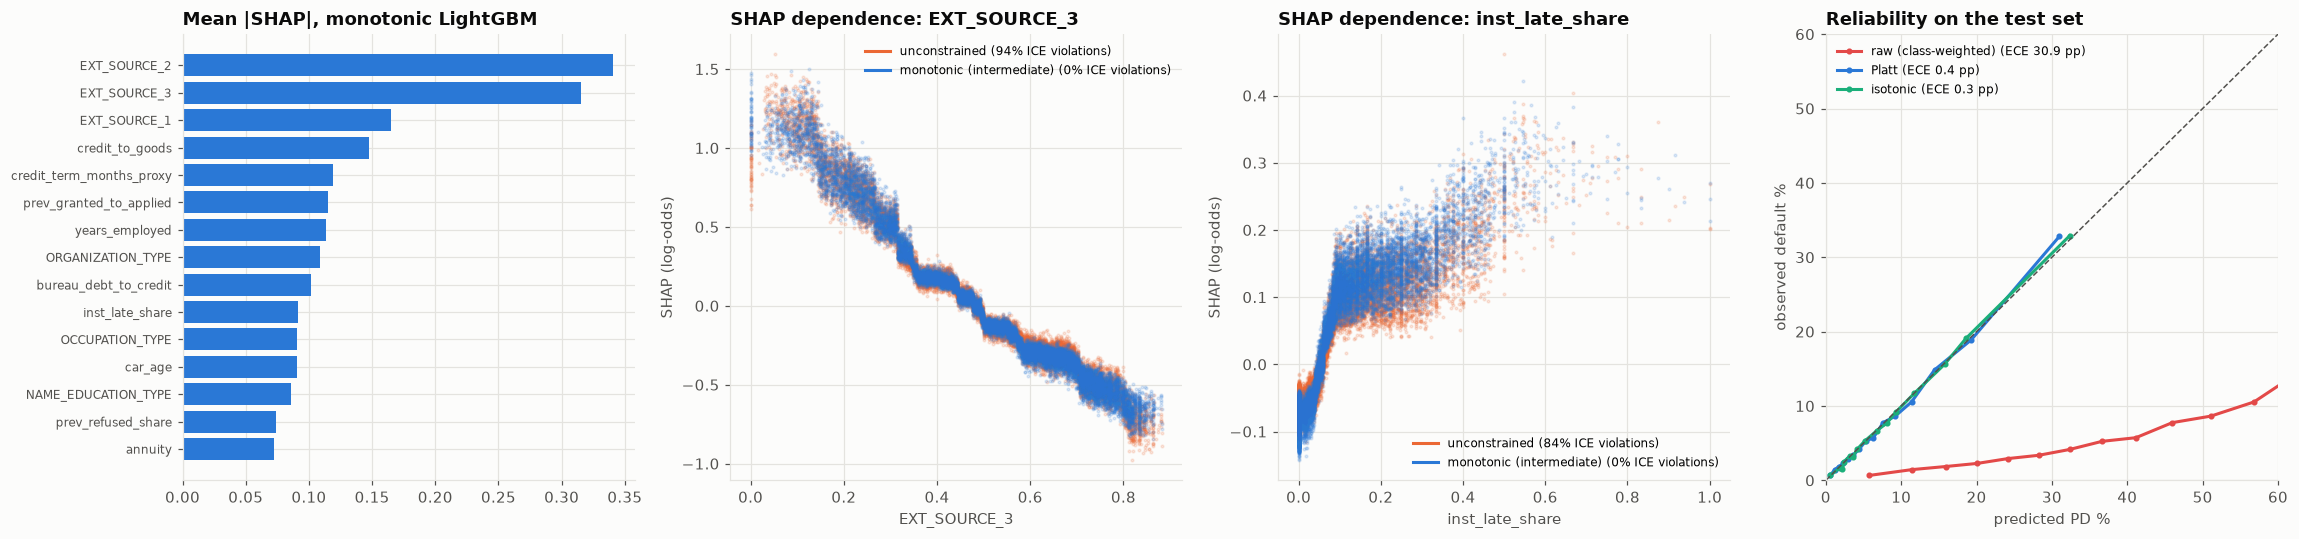

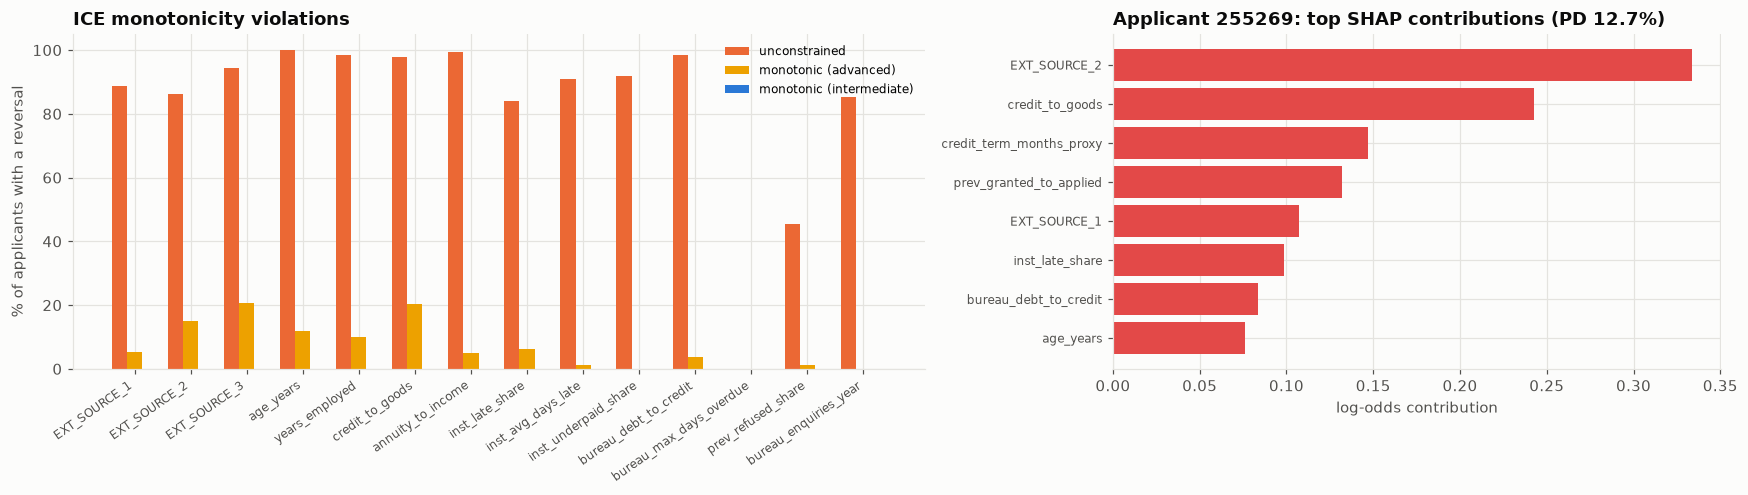

In [11]:
fig, axes = plt.subplots(1, 4, figsize=(21, 5))
ax = axes[0]
top = shap_imp.head(15).iloc[::-1]
ax.barh(top.index, top["LightGBM monotonic"], color=PALETTE[0])
ax.set_title("Mean |SHAP|, monotonic LightGBM")
ax.tick_params(axis="y", labelsize=8)
for ax, f in zip(axes[1:3], ["EXT_SOURCE_3", "inst_late_share"]):
    for n, col in [
        ("LightGBM unconstrained", PALETTE[1]),
        ("LightGBM monotonic", PALETTE[0]),
    ]:
        x = shap_sample[f]
        ax.scatter(x, contrib[n][f], s=3, alpha=0.15, color=col)
        grid, mean_curve = ice_curves[(f, n)]
        short = (
            "unconstrained"
            if n.endswith("unconstrained")
            else "monotonic (intermediate)"
        )
        ax.plot(
            [],
            [],
            color=col,
            label=(
                f"{short} ({ice.loc[f, '% violated · ' + short]:.0f}% ICE"
                " violations)"
            ),
        )
    ax.set_title(f"SHAP dependence: {f}")
    ax.set_xlabel(f)
    ax.set_ylabel("SHAP (log-odds)")
    ax.legend(fontsize=8, markerscale=3)
ax = axes[3]
for k, col in [
    ("raw (class-weighted)", PALETTE[7]),
    ("Platt", PALETTE[0]),
    ("isotonic", PALETTE[2]),
]:
    obs, pred = calibration_curve(
        y_te, pd_versions[k], n_bins=15, strategy="quantile"
    )
    ax.plot(
        pred * 100,
        obs * 100,
        "o-",
        ms=3,
        color=col,
        label=f"{k} (ECE {calibration.loc[k, 'ECE (pp)']:.1f} pp)",
    )
ax.plot([0, 60], [0, 60], color=INK_2, ls="--", lw=1)
ax.set_xlim(0, 60)
ax.set_ylim(0, 60)
ax.set_title("Reliability on the test set")
ax.set_xlabel("predicted PD %")
ax.set_ylabel("observed default %")
ax.legend(fontsize=8)
plt.tight_layout()
save_fig(fig, "01_shap_monotonic_calibration")
plt.show()

fig, axes = plt.subplots(
    1, 2, figsize=(16, 4.6), gridspec_kw={"width_ratios": [1.4, 1]}
)
ax = axes[0]
show = ice.copy()
xi = np.arange(len(show))
for k, (col_name, col) in enumerate([
    ("% violated · unconstrained", PALETTE[1]),
    ("% violated · monotonic (advanced)", PALETTE[3]),
    ("% violated · monotonic (intermediate)", PALETTE[0]),
]):
    ax.bar(
        xi + (k - 1) * 0.27,
        show[col_name],
        0.27,
        color=col,
        label=col_name.split("· ")[1],
    )
ax.set_xticks(xi, show.index, rotation=35, ha="right", fontsize=8)
ax.set_ylabel("% of applicants with a reversal")
ax.set_title("ICE monotonicity violations")
ax.legend(fontsize=8)
ax = axes[1]
loc = reasons.head(8).iloc[::-1]
ax.barh(
    loc.index,
    loc.values,
    color=[PALETTE[7] if v > 0 else PALETTE[2] for v in loc.values],
)
ax.set_title(
    f"Applicant {int(applicant['SK_ID_CURR'].iloc[0])}: top SHAP contributions"
    f" (PD {PD_FINAL[j]:.1%})"
)
ax.set_xlabel("log-odds contribution")
ax.tick_params(axis="y", labelsize=8)
plt.tight_layout()
save_fig(fig, "02_ice_and_local_explanation")
plt.show()

## 10. Reading the results and limitations

Home Credit applications, 184,506 for training, 61,502 for calibration and 61,503 for the test (8.1% default):

**Boosting adds about 7 Gini points over logistic regression.** On the test set, unconstrained LightGBM reaches a Gini of 0.556 and the logistic benchmark on its top-20 features 0.487. PR-AUC improves from 0.22 to 0.27. The history tables matter: the credit-to-goods ratio, the implied loan term, previous grants vs applications, the bureau debt ratio and instalment lateness all rank among the top drivers. Even so, the three external bureau scores dominate (mean |SHAP| 0.34, 0.32 and 0.17).

- **Monotonicity costs little.** The constrained model's Gini is 0.549. The loss in AUC is 0.0035, statistically significant (95% CI −0.0050 to −0.0022) but small next to the 0.07 gain over the logistic model.

**Unconstrained trees reverse almost everywhere.** For 84–100% of applicants the unconstrained model's PD falls somewhere as their late-payment share rises, or rises as an external score improves, by more than 0.1 percentage point. The dependence plots show these are small wiggles around a clear trend rather than large reversals.

Still, every one would be a "you would have got a better rate with a worse history" complaint, and a validator would reject it.

**The ICE test caught a library behaviour, not just a modelling one.** With LightGBM's `advanced` constraint method, up to 21% of applicants still showed reversals on the constrained features (EXT_SOURCE_3 and credit-to-goods). A small experiment isolated the cause: in this LightGBM version (4.7) the `advanced` method does not enforce the constraint when the constrained feature has missing values.

Here EXT_SOURCE_1, years employed and the history aggregates are often missing. The `intermediate` method gives **no violation above 0.1 points on any feature**, at about the same accuracy, and is the one used. Tiny reversals below that threshold can remain. The lesson for model validation is to test monotonicity directly on the fitted model and not rely on the configuration flag.

**Class weighting destroys calibration; one Platt step restores it.** The weighted model's average PD is 39% against an 8.1% default rate (ECE 31 points, Brier 0.184). Platt scaling on the separate calibration sample brings the average PD to 8.08%, the ECE to 0.4 points and the Brier score to 0.067, without changing the ranking.

Isotonic regression is as good here (ECE 0.3 points) because 61,000 calibration observations are plenty; with less data, Platt's two parameters are the safer choice.

- **Each decision can be explained.** For the declined applicant closest to the 80%-approval cutoff (PD 12.7%), the reasons are a weak external score 2 (+0.33 log-odds), a loan larger than the price of the goods (credit/goods 1.40), a long implied term and a missing external score 1. These map directly to adverse-action reasons.

**The gender screen is borderline.** Gender is not an input, but at the 80% cutoff women are approved at 82.8% and men at 74.5%, an adverse impact ratio of 0.90. That passes the four-fifths rule. The gap tracks real risk: men default at 10.4% against 6.9% for women. A fair-lending review would still check which proxies (occupation, organisation type, car ownership) carry the difference.

**Limitations**

- Random split of one application period; Home Credit's data have no application date, so there is no out-of-time test.
- The external scores are bureau scores whose construction is unknown; a production model would need their documentation and their own monitoring.
- The constraints are imposed one feature at a time; they do not stop interactions from creating non-intuitive joint effects.

In [12]:
disc.to_csv(OUT_DIR / "discrimination.csv")
ice.to_csv(OUT_DIR / "ice_monotonicity_violations.csv")
calibration.to_csv(OUT_DIR / "calibration.csv")
shap_imp.to_csv(OUT_DIR / "shap_importance.csv")
local.to_csv(OUT_DIR / "local_explanation.csv")
grp.to_csv(OUT_DIR / "approval_by_gender.csv")
print("Outputs written:", ", ".join(sorted(p.name for p in OUT_DIR.iterdir())))

Outputs written: 01_shap_monotonic_calibration.png, 02_ice_and_local_explanation.png, approval_by_gender.csv, calibration.csv, discrimination.csv, ice_monotonicity_violations.csv, local_explanation.csv, shap_importance.csv


## References

### Finance and regulation

- Board of Governors of the Federal Reserve System. (2011). *Supervisory guidance on model risk management* (SR 11-7). https://www.federalreserve.gov/boarddocs/srletters/2011/sr1107.htm
- Lessmann, S., Baesens, B., Seow, H.-V., & Thomas, L. C. (2015). Benchmarking state-of-the-art classification algorithms for credit scoring: An update of research. *European Journal of Operational Research, 247*(1), 124–136. https://doi.org/10.1016/j.ejor.2015.05.030
- Bussmann, N., Giudici, P., Marinelli, D., & Papenbrock, J. (2021). Explainable machine learning in credit risk management. *Computational Economics, 57*(1), 203–216. https://doi.org/10.1007/s10614-020-10042-0

### Machine learning and deep learning

- Ke, G., Meng, Q., Finley, T., Wang, T., Chen, W., Ma, W., Ye, Q., & Liu, T.-Y. (2017). LightGBM: A highly efficient gradient boosting decision tree. *Advances in Neural Information Processing Systems, 30*. https://proceedings.neurips.cc/paper/2017/hash/6449f44a102fde848669bdd9eb6b76fa-Abstract.html
- Lundberg, S. M., Erion, G., Chen, H., DeGrave, A., Prutkin, J. M., Nair, B., … Lee, S.-I. (2020). From local explanations to global understanding with explainable AI for trees. *Nature Machine Intelligence, 2*(1), 56–67. https://doi.org/10.1038/s42256-019-0138-9
- Zadrozny, B., & Elkan, C. (2002). Transforming classifier scores into accurate multiclass probability estimates. In *Proceedings of the Eighth ACM SIGKDD International Conference on Knowledge Discovery and Data Mining*. https://doi.org/10.1145/775047.775151
- Goldstein, A., Kapelner, A., Bleich, J., & Pitkin, E. (2015). Peeking inside the black box: Visualizing statistical learning with plots of individual conditional expectation. *Journal of Computational and Graphical Statistics, 24*(1), 44–65. https://doi.org/10.1080/10618600.2014.907095
- Guo, C., Pleiss, G., Sun, Y., & Weinberger, K. Q. (2017). On calibration of modern neural networks. In *Proceedings of the 34th International Conference on Machine Learning*. https://arxiv.org/abs/1706.04599